### Trajectory Analysis and Integration of Modalities using Kidney IgAN (Pathomics) Data with PILOT

<div class="alert alert-block alert-info">
<b>PILOT</b>

Welcome to the PILOT Package Tutorial for pathomics Data!
With this tutorial, we learn not only how to analyze the Pathomics Data but also how to integrate multimodal data with PILOT. 
 
You can find the pathomics data [here](https://github.com/CostaLab/PILOT/tree/main/Tutorial/Datasets).

</div>

In [1]:
import pilotpy as pl
import scanpy as sc

#### Kidney_IgAN Tubuli (first modality)

##### Reading Anndata
<div class="alert alert-block alert-info">
The Anndata (h5ad) file is in the Datasets folder.
</div>

In [2]:
adata_T=sc.read_h5ad('Datasets/Kidney_IgAN_T.h5ad') 

#### Loading the required information and computing the Wasserstein distance:
<div class="alert alert-block alert-info"> In order to work with PILOT, ensure that your Anndata object is loaded and contains the required information.
    
Use the following parameters to configure PILOT for your analysis (Setting Parameters):
    
- adata: Pass your loaded Anndata object to PILOT.
    
- emb_matrix: Provide the name of the variable in the obsm level that holds the dimension reduction ( PCA representation).
    
- clusters_col: Specify the name of the column in the observation level of your Anndata that corresponds to cell types or clusters.
    
- sample_col: Indicate the column name in the observation level of your Anndata that contains information about samples or patients.
    
- status: Provide the column name that represents the status or disease (e.g., "control" or "case").
  
</div>

In [3]:
pl.tl.wasserstein_distance(
    adata_T,
    clusters_col = 'Cell_type',
    sample_col = 'sampleID',
    status = 'status', 
    data_type = 'Pathomics'
    )

##### plotting the Cost matrix and the Wasserstein distance:
<div class="alert alert-block alert-info"> 
 Here we show the heatmaps of the Cost matrix (cells) and Wasserstein distance (samples).  At this point, you should have a 'Results_PILOT' folder inside the folder where you are running your analysis, which includes all the plots created by PILOT. To plot only one of them, use `pl.pl.heatmap_cost(adata)` or `pl.pl.heatmap_wasserstein(adata)`. The size of the heatmaps follows the number of cell types and samples; it can be changed with `figsize`.
</div>

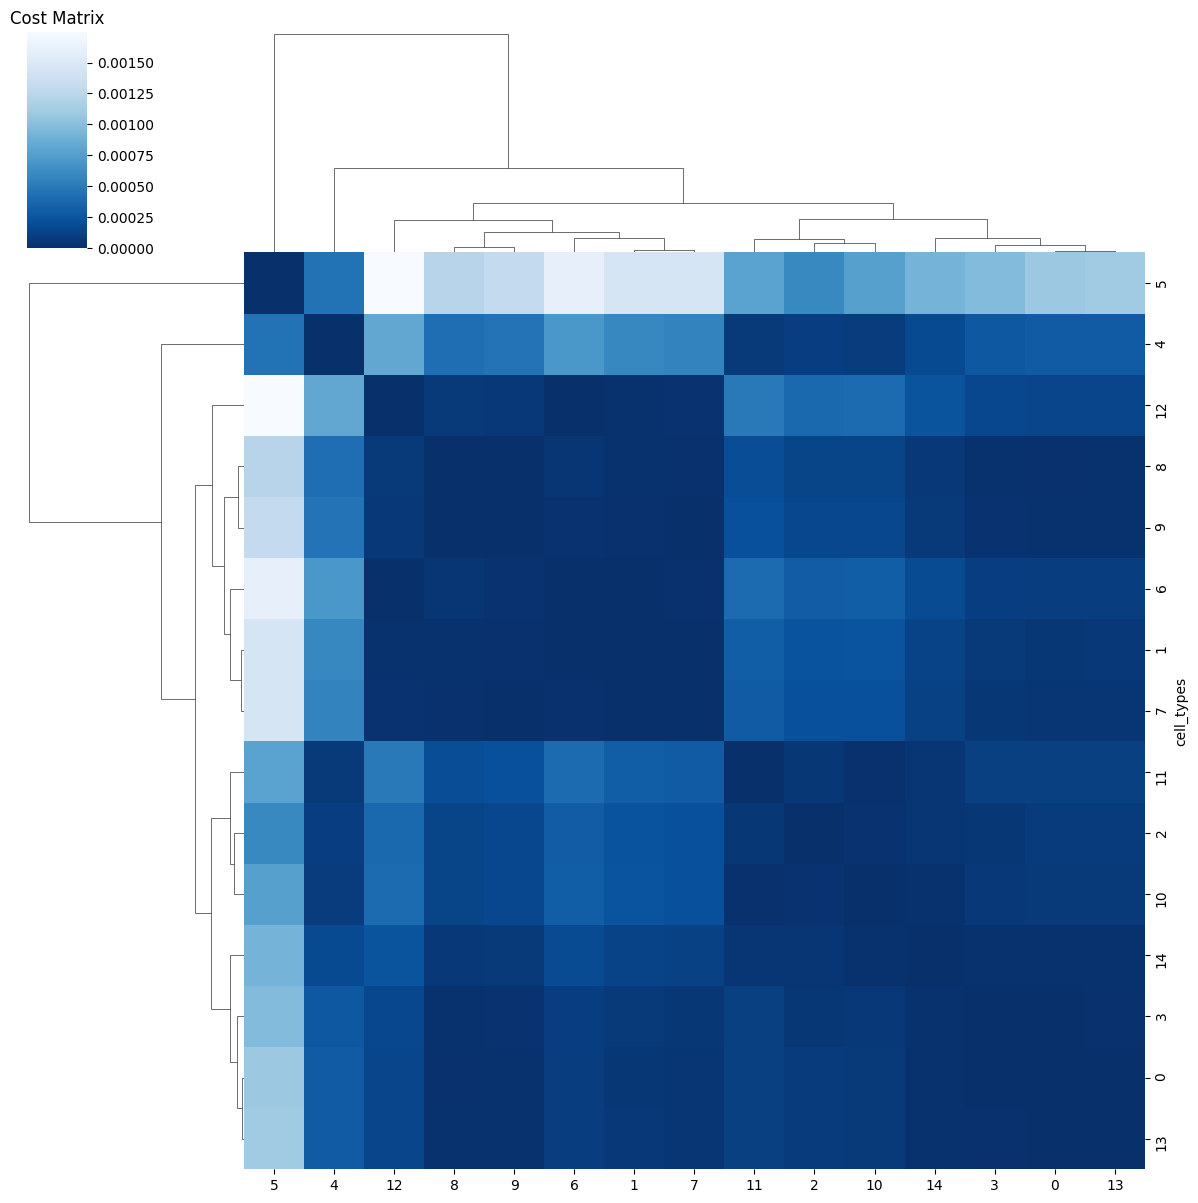

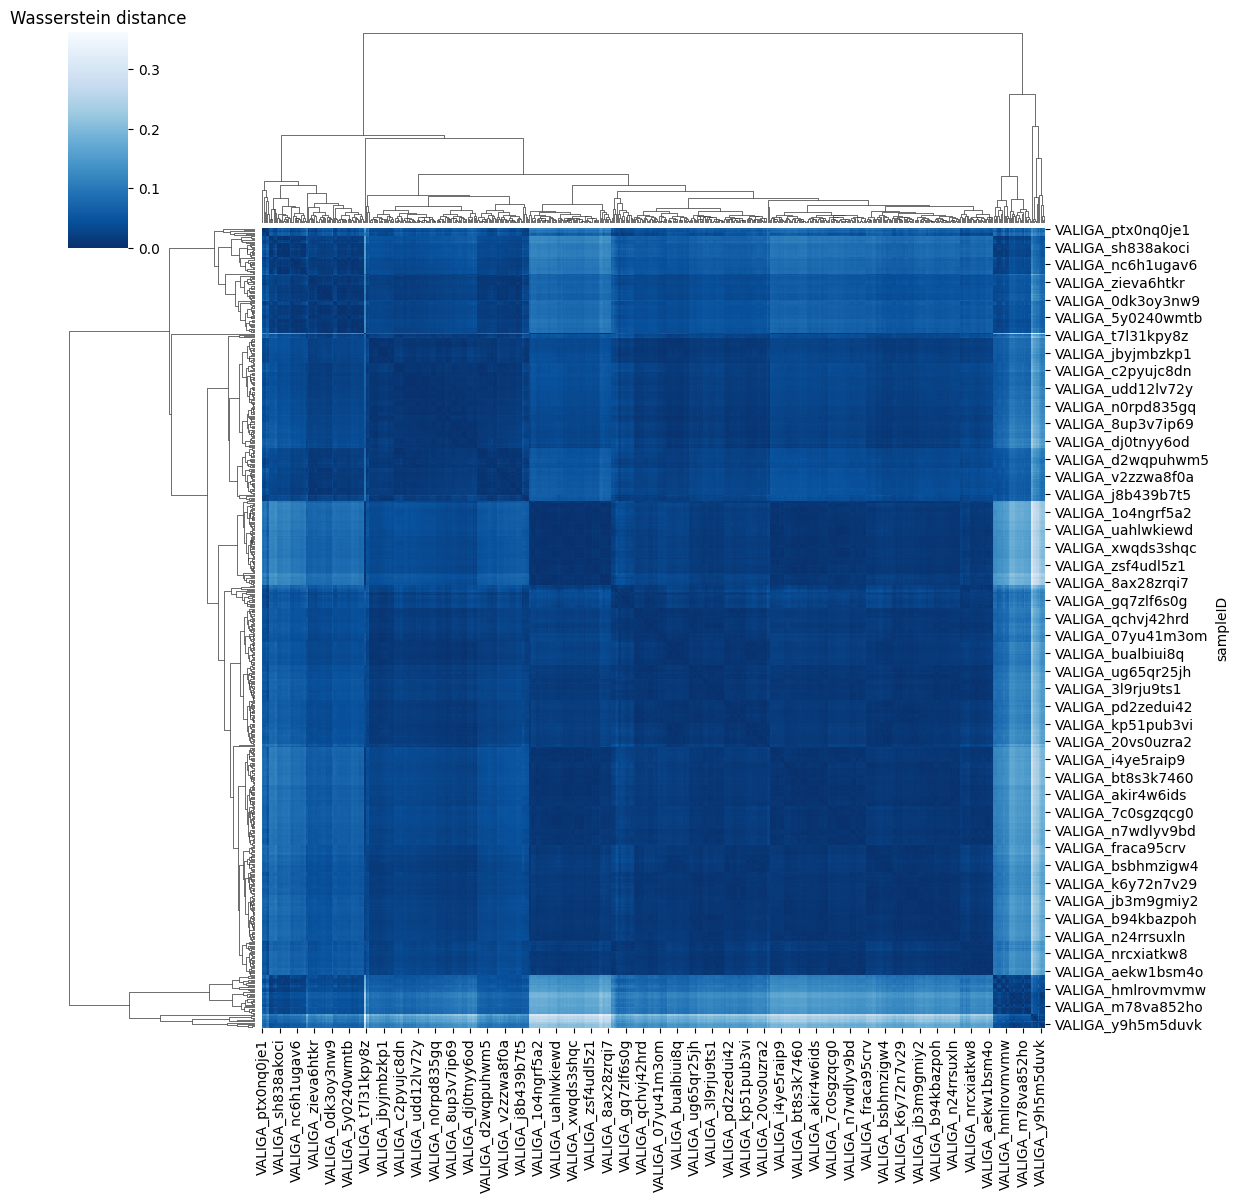

In [4]:
pl.pl.heatmaps(adata_T)

##### Trajectory:
<div class="alert alert-block alert-info"> 
 Here we show the Diffusion map of Wasserstein distance. In the upcoming trajectory analysis, the labels "<30" mean an eGFR level below 30 (considered as Low), "30-60" denotes a reduced eGFR range (marked as Reduced), and ">60" indicates a normal eGFR level
The colors are chosen automatically from the number of groups, so there is no need to give them. Useful options:

- `legend_order`: order of the groups in the legend, e.g. the control group first.
- `colors`: your own colors, as a list or a dict, e.g. `{'control': 'blue'}`.
- `location_labels` and `legend_bbox`: position of the legend, e.g. `location_labels = 'upper left', legend_bbox = (1.02, 1)` puts it outside the plot.
- `clusters`: color the samples by another sample-level column of `adata.obs` (e.g. `clusters = 'sex'`), without computing the trajectory again.
- `point_size`, `figsize`, `font_size`, `plot_titel`, `label_act` (show the sample names).

The trajectory is computed once and saved in the object. Running `pl.pl.trajectory` again (e.g. with other colors) gives the same picture. It is computed again only when the Wasserstein distance or the diffusion map parameters (`knn`, `epsilon`, `alpha`, `n_evecs`) change.
</div>

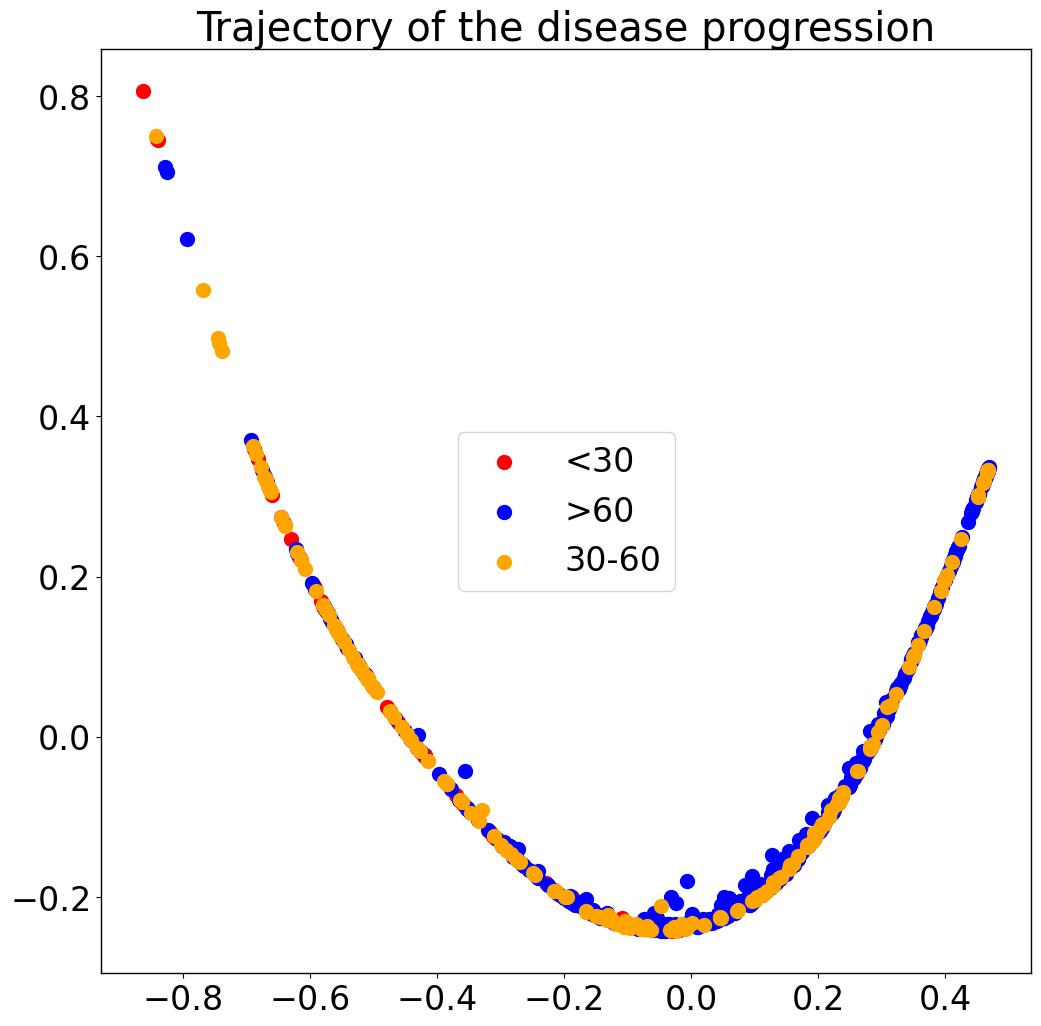

In [5]:
pl.pl.trajectory(adata_T, legend_order = ['>60', '30-60', '<30'])

##### UMAP of the samples:
<div class="alert alert-block alert-info">
PILOT can also show the samples (patients) in a UMAP computed from the Wasserstein distances. The colors are the same as in the trajectory, so both plots can be compared directly. The same legend options as in `pl.pl.trajectory` can be used.
</div>

In [ ]:
pl.pl.umap_samples(adata_T, legend_order = ['>60', '30-60', '<30'])

#### Kidney_IgAN Glomeruli (second modality)

##### Reading Anndata
<div class="alert alert-block alert-info">
The Anndata (h5ad) file is in the Datasets folder.
   </div>

In [6]:
adata_G=sc.read_h5ad('Datasets/Kidney_IgAN_G.h5ad') #First read the object

In [7]:
pl.tl.wasserstein_distance(
    adata_G,
    clusters_col = 'Cell_type',
    sample_col = 'sampleID',
    status = 'status',
    data_type = 'Pathomics'
    )

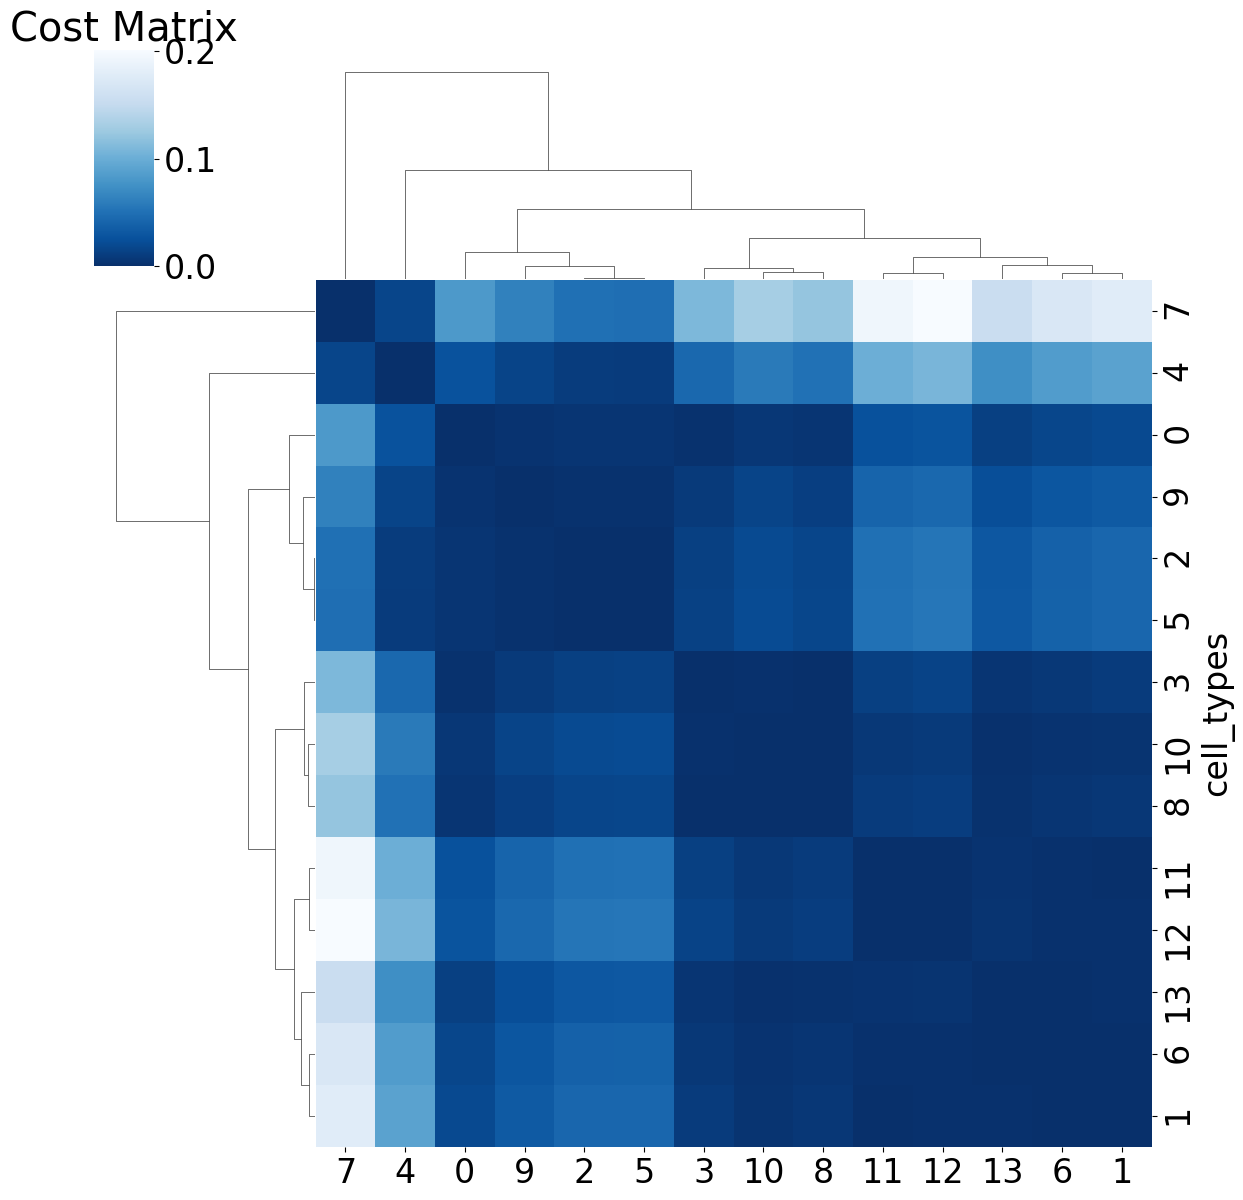

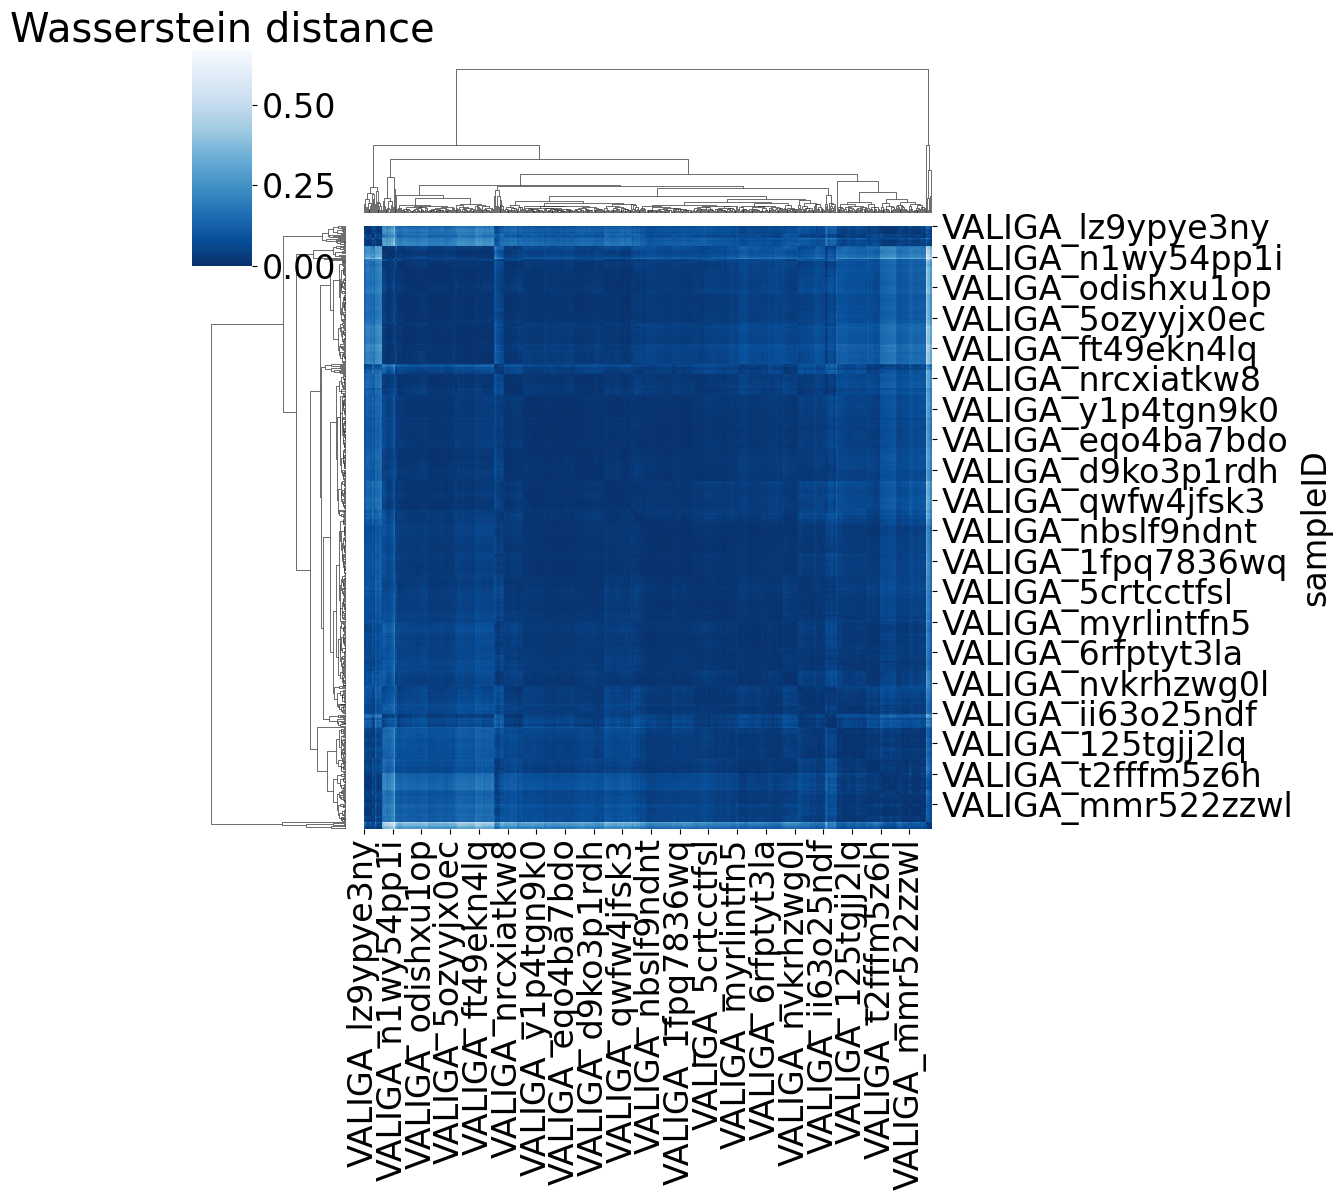

In [8]:
pl.pl.heatmaps(adata_G)

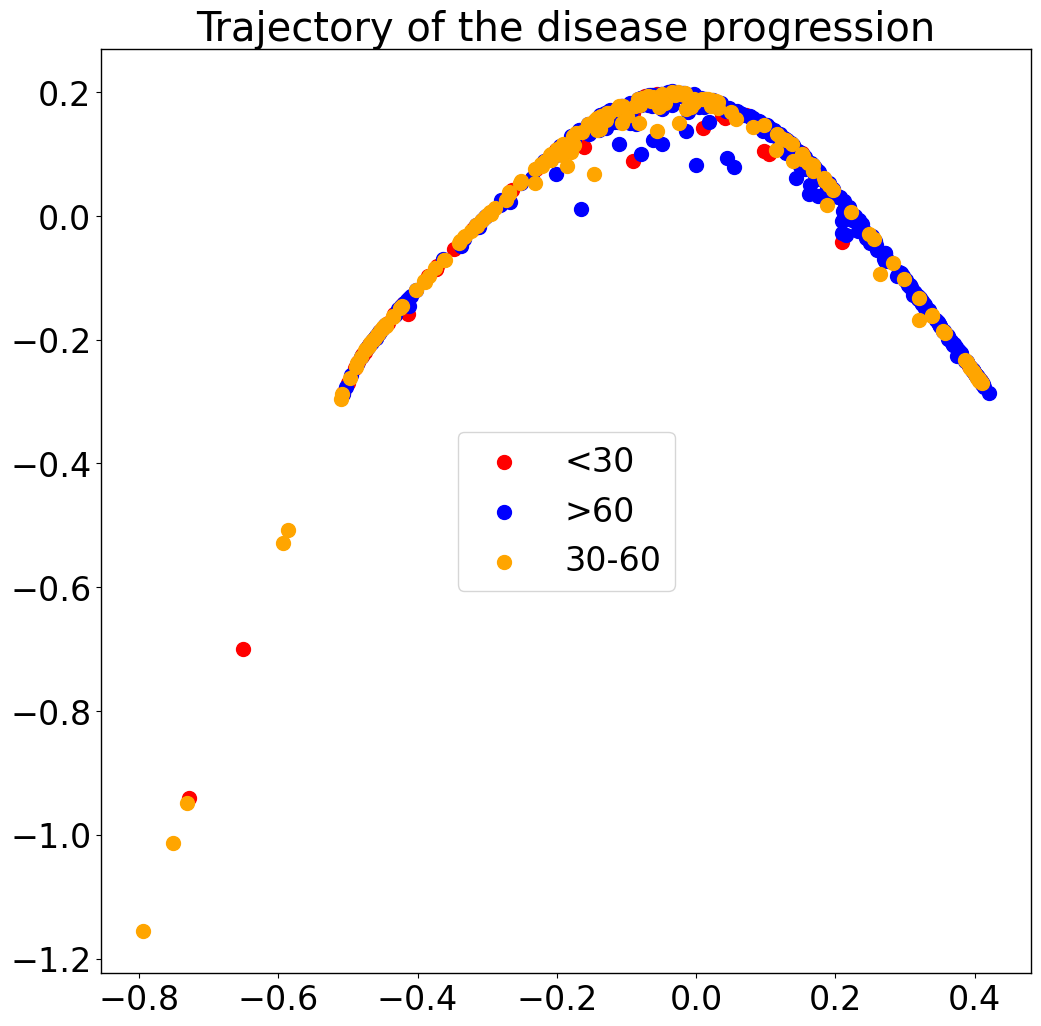

In [9]:
pl.pl.trajectory(adata_G, legend_order = ['>60', '30-60', '<30'])

In [ ]:
pl.pl.umap_samples(adata_G, legend_order = ['>60', '30-60', '<30'])

####  Integration of modalities:
<div class="alert alert-block alert-info"> 
Here, we integrate the distances from the first (Tubuli) and second (Glomeruli) modalities. We get the sum of the distances of samples.
</div>

In [10]:
adata_Com = adata_G
adata_Com.uns['EMD'] = adata_G.uns['EMD'] + adata_T.uns['EMD']

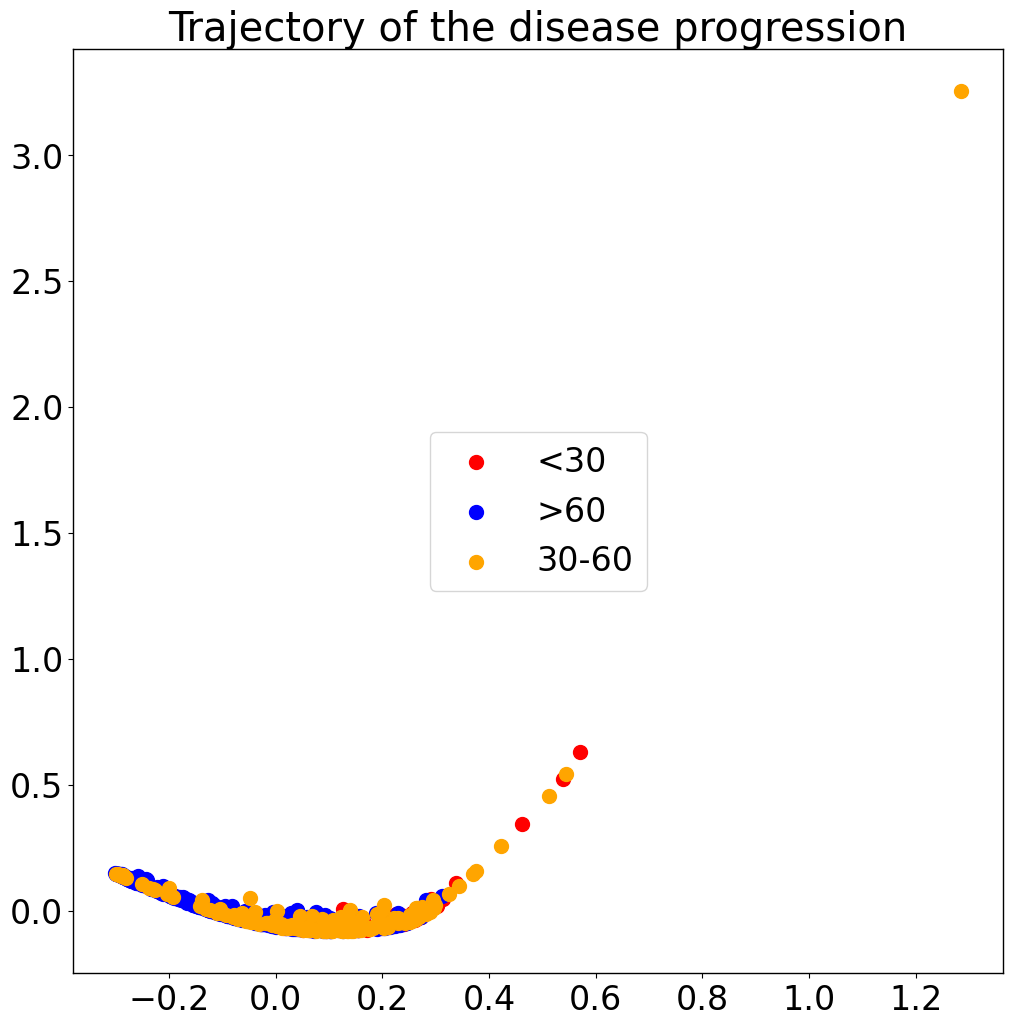

In [11]:
pl.pl.trajectory(adata_Com, legend_order = ['>60', '30-60', '<30'])

##### UMAP of the samples:
<div class="alert alert-block alert-info">
PILOT can also show the samples (patients) in a UMAP computed from the Wasserstein distances. The colors are the same as in the trajectory, so both plots can be compared directly. The same legend options as in `pl.pl.trajectory` can be used.
</div>

In [ ]:
pl.pl.umap_samples(adata_Com, legend_order = ['>60', '30-60', '<30'])

####  Fit a principal graph:
<div class="alert alert-block alert-info"> 
The difussion map creates an embedding that potentially reveals a trajectory in the data. Next, PILOT explores EIPLGraph to find the structure of the trajectory. An important parameter is the source_node, which indicates the start of the trajectory. Here, the root is chosen automatically near the samples with a normal eGFR (">60"). This method returns ranked samples, which we define as a disease progression score (t = t1, ..., tn), where tl represents the ranking of the nth sample. With `source_node = 'auto'`, PILOT chooses the root automatically: the end node of the graph from which the control samples (given by `root_status`) come first along the trajectory. You can also give the node number yourself, e.g. `source_node = 7` (the node numbers are shown in the plot). The graph is fitted with a fixed random seed. In a new Python session the graph can still change slightly, so the node numbers can change; `source_node = 'auto'` does not depend on them. Always check the plot. The steps can also be run one by one: `pl.tl.fit_principal_graph`, `pl.pl.principal_graph` and `pl.tl.compute_pseudotime`.
</div>


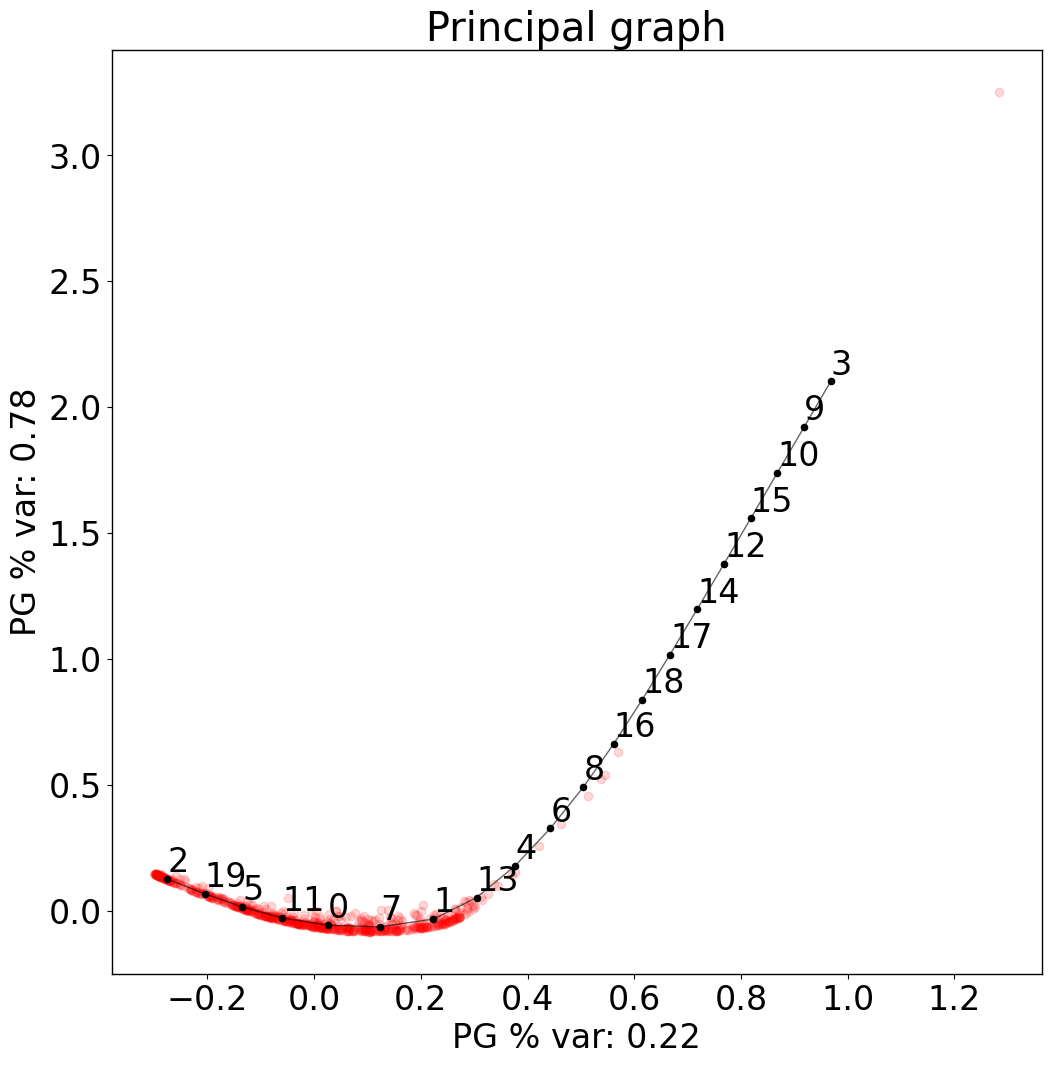

In [12]:
pl.pl.fit_pricipla_graph(adata_Com, source_node = 'auto', root_status = '>60')

##### Cell-type Importance Glomeruli:

By default the x-axis is the order of the samples along the trajectory (1, 2, 3, ...). Use `x_axis = 'pseudotime'` to use the pseudotime values instead. The size of the figure follows the number of cell types; the labels and fonts can be changed with `xlabel`, `ylabel`, `label_fontsize`, `tick_fontsize` and `title_fontsize`. The steps can also be run one by one: `pl.tl.cell_importance_calculation`, `pl.pl.heatmap_proportions` and `pl.pl.cell_importance_grid` (or `pl.pl.cell_importance_plot` for one file per cell type).

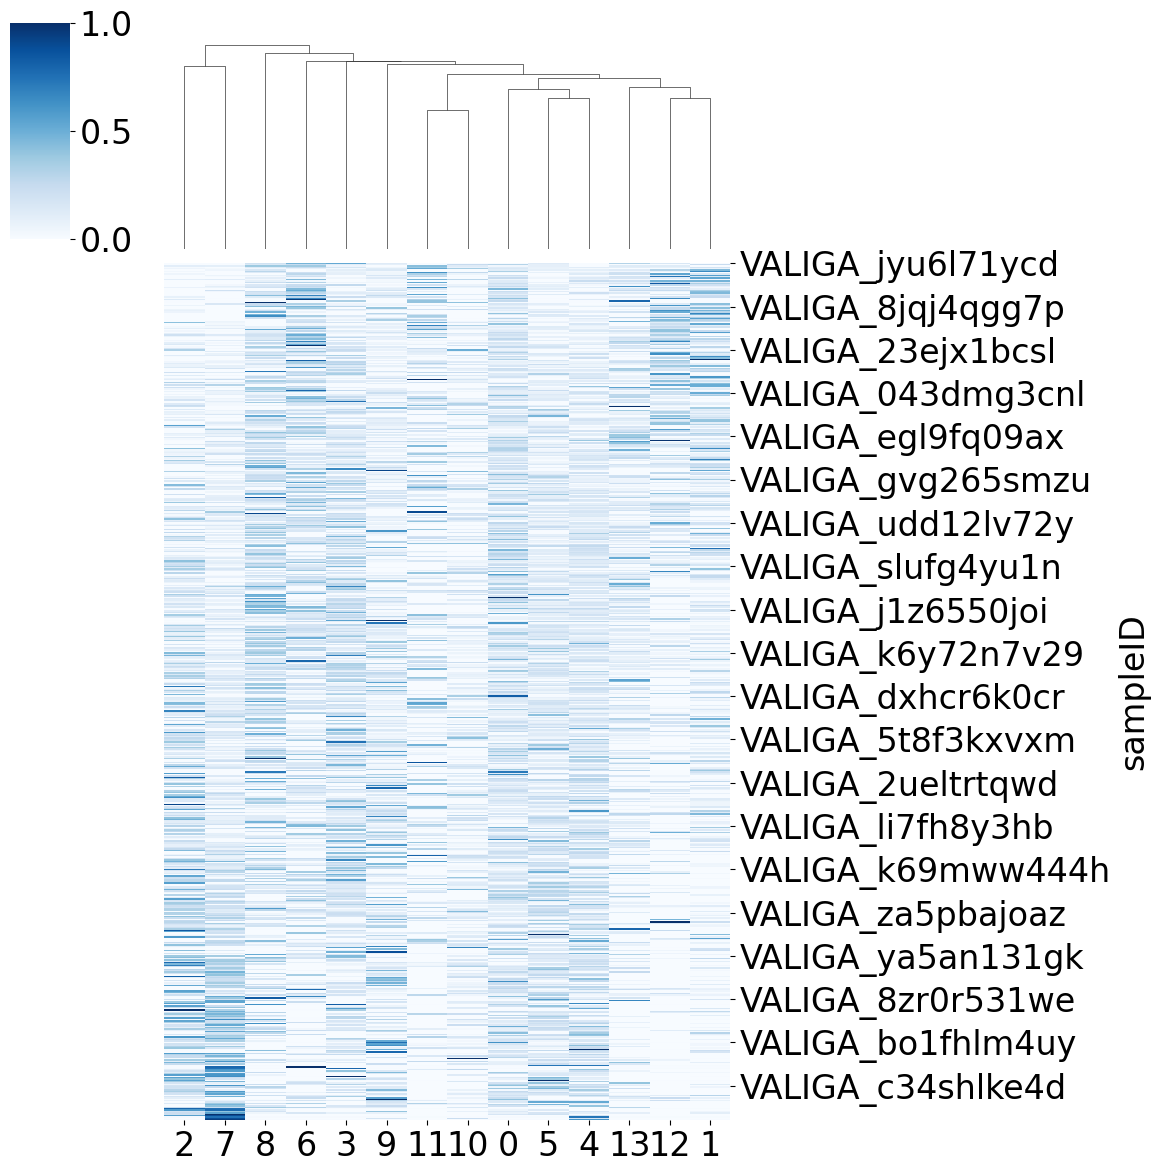

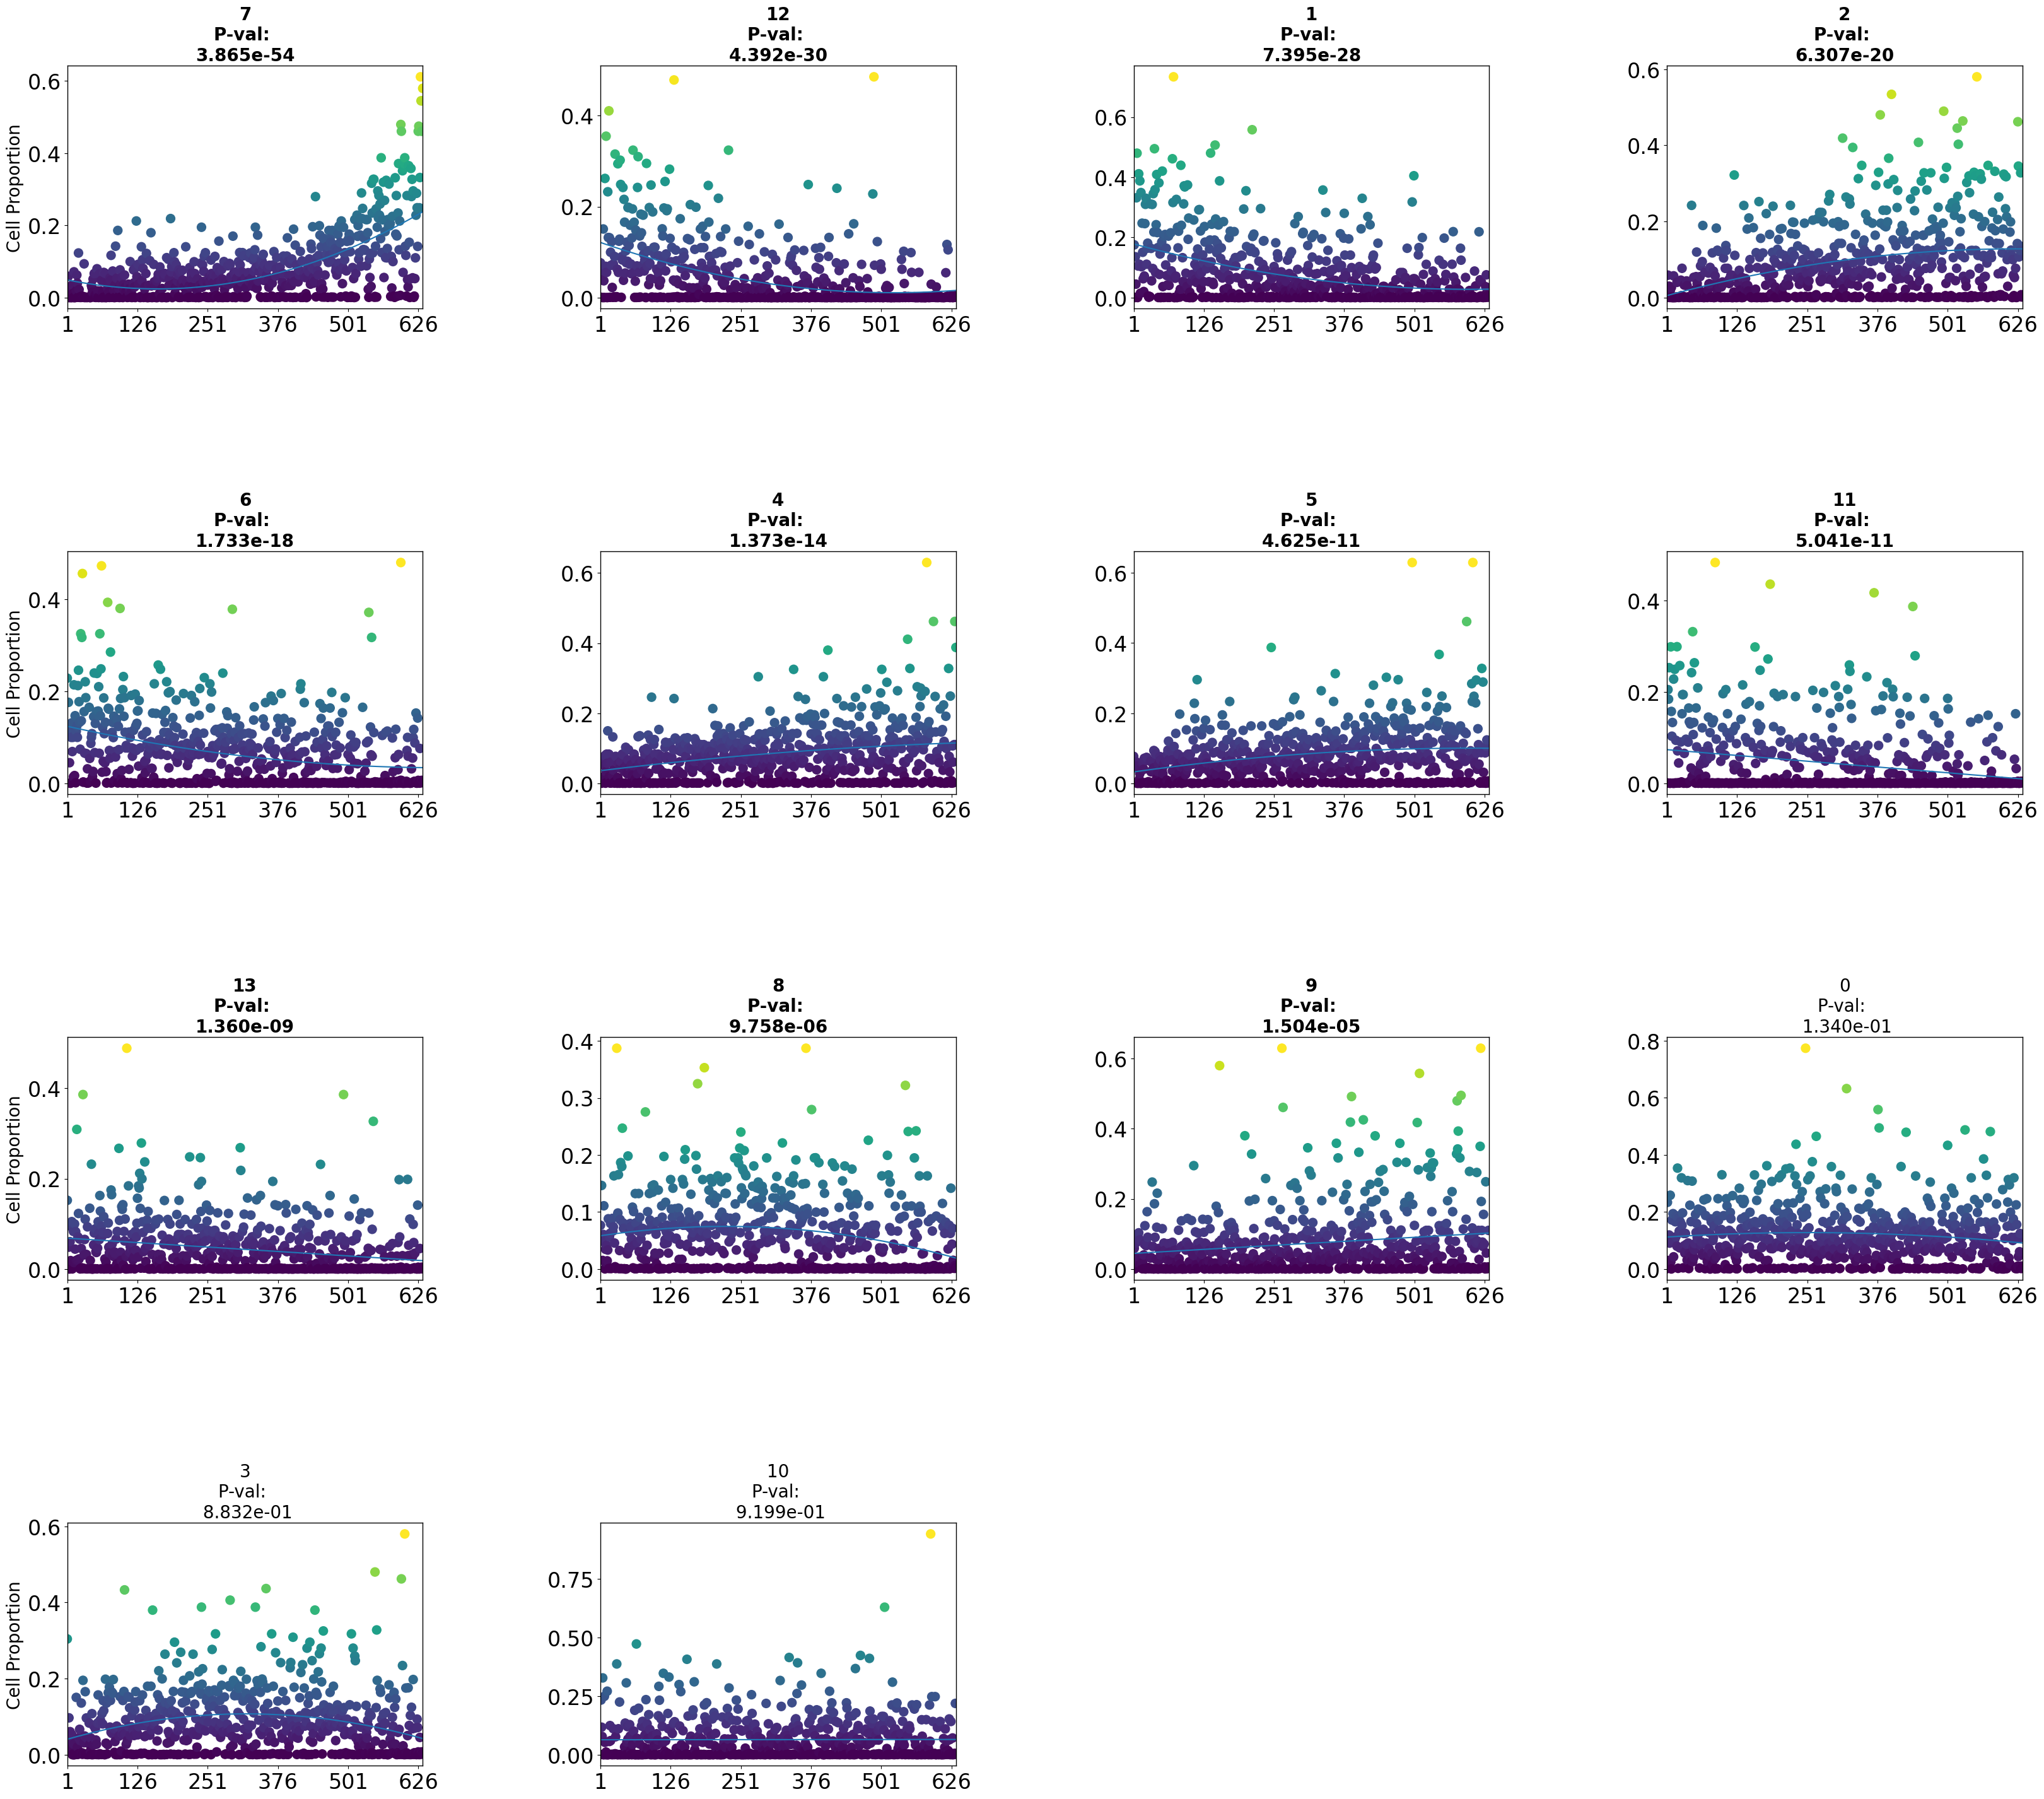

In [13]:
pl.tl.cell_importance(adata_Com, xlim = 125)

#### Feature selection for Glomeruli based on Combination:

##### Saving morphological features and maps them with the obtained order by PILOT  (for Glomeruli):

<div class="alert alert-block alert-info">     
In this step, morphological features are extracted from all clusters and linked to pseudotime using the PILOT trajectory order.

- The "extract_cells_from_pathomics" function creates a 'cells' folder inside the 'Results_PILOT' folder to store these morphological features and corresponding pseudotime values as 'All.csv'.
</div>

In [14]:
pl.tl.extract_cells_from_pathomics(adata_Com)

##### Getting the log scale of features 

In [15]:
data=pl.tl.norm_morphological_features(
 column_names = ['glom_sizes', 'glom_distance_to_closest_glom','glom_diameters','glom_tuft_sizes',
                 'glom_bowman_sizes'],
 name_cell = 'All'
    )

##### Morphological features changes for Glomeruli:

<div class="alert alert-block alert-info">
      
 Firstly, we should note that for pathomics data, instead of using cluster-specific changes for features/genes (please see MI tutorial analysis), we use the fit models to find the structural changes. 
    
We apply the morphological_features_importance function to catch the features/structures that are changing over the trajectory (combination) for Glomeruli.
</div>

Name of Cluster : All
Sparsity:6.486269746268921e-05
For this cell_type, p-value of  14 genes are statistically significant.
  Expression pattern  count
0        linear down      6
1          linear up      4
2     quadratic down      2
3       quadratic up      2
data saved successfully


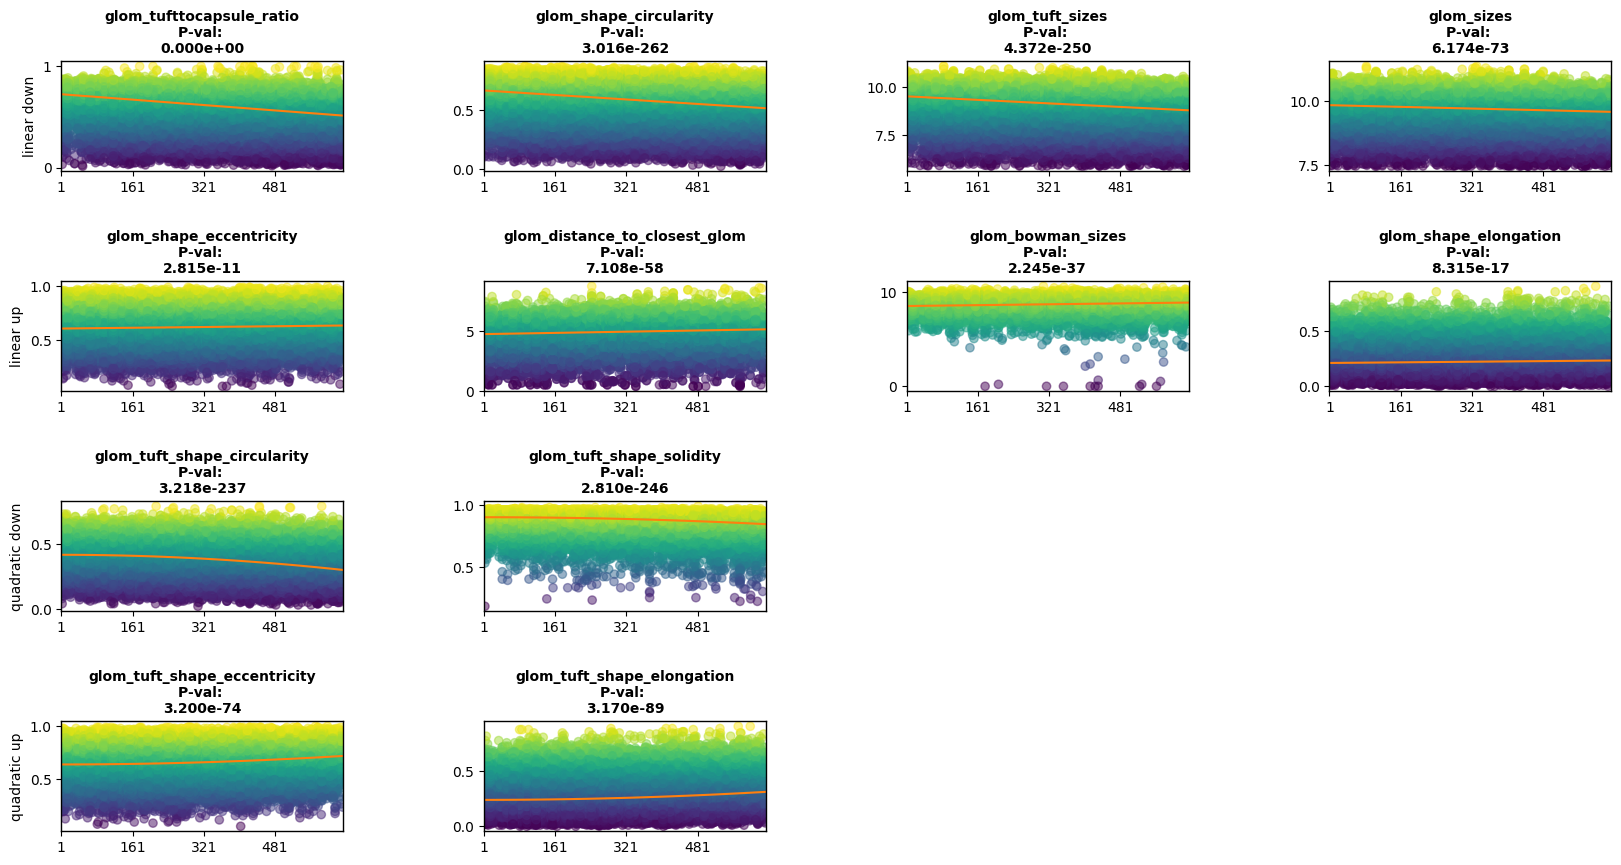

In [16]:
pl.tl.morphological_features_importance(data, height = 10, x_lim = 160, width = 20)    

#### Feature selection for Tubuli based on Combination
<div class="alert alert-block alert-info">

We repeat the same process for Tubuli.
</div>

#### Saving morphological features and map them with the obtained order by PILOT  (for Tubuli):


In [17]:
adata_T.uns['orders'] = adata_Com.uns['orders']
pl.tl.extract_cells_from_pathomics(adata_T)

#####  Getting the log scale of features 

In [18]:
data=pl.tl.norm_morphological_features(
 column_names = ['tubule_diameters', 'tubule_sizes', 'tubule_distance_to_closest_instance'],
 name_cell = 'All'
    )

##### Morphological features changes for Tubuli

Name of Cluster : All
Sparsity:0.0
For this cell_type, p-value of  3 genes are statistically significant.
  Expression pattern  count
0        linear down      2
1          linear up      1
data saved successfully


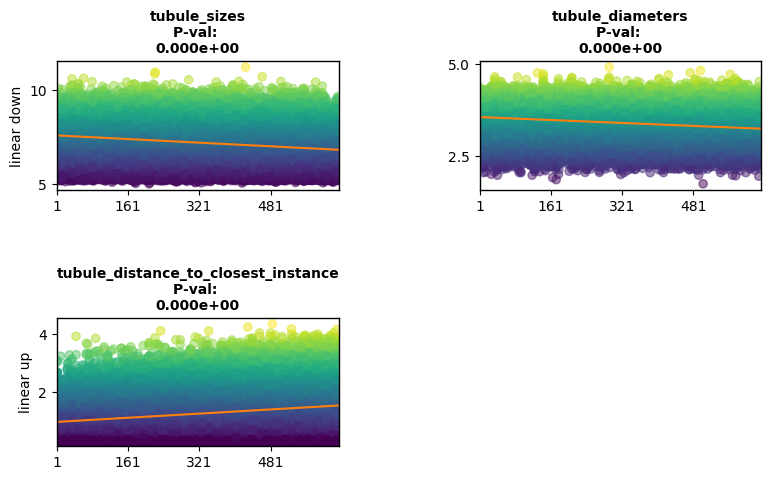

In [19]:
pl.tl.morphological_features_importance(data, x_lim = 160, height = 5)    